In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR MODELOS

reg_log_diab_class_weight = joblib.load("../models/reg_log_diab_class_weight.joblib")
reg_log_diab = joblib.load("../models/reg_log_diab.joblib")
reg_log_diab_smote = joblib.load("../models/reg_log_diab_smote.joblib")

In [3]:
# CARGAR LOS DATOS DE TEST 

X_test_diab = pd.read_csv("../data/processed/X_test_diab_df.csv")
y_test_diab = pd.read_csv("../data/processed/y_test_diab.csv")
X_train_diab = pd.read_csv("../data/processed/X_train_diab_df.csv")
y_train_diab = pd.read_csv("../data/processed/y_train_diab.csv")

# REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9687    0.7143    0.8223      3773
           1     0.2256    0.7830    0.3503       401

    accuracy                         0.7209      4174
   macro avg     0.5972    0.7487    0.5863      4174
weighted avg     0.8973    0.7209    0.7769      4174

ROC-AUC Score: 0.8146


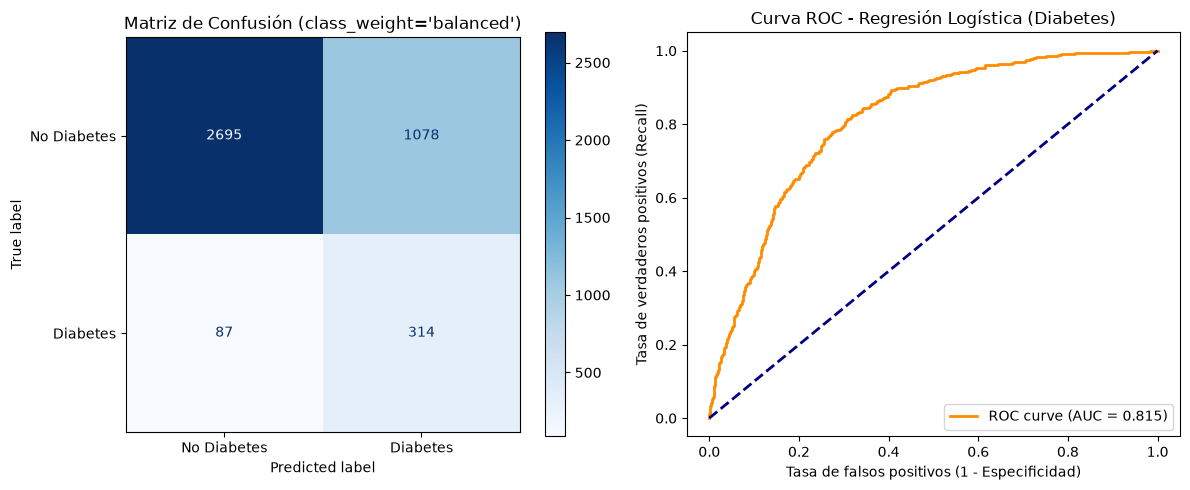

In [44]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_diab = reg_log_diab_class_weight.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab_class_weight.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab_class_weight.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8017 | Recall test: 0.7830
Diferencia: 0.0187


INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9743    0.6721    0.7955      3773
           1     0.2126    0.8329    0.3387       401

    accuracy                         0.6876      4174
   macro avg     0.5934    0.7525    0.5671      4174
weighted avg     0.9011    0.6876    0.7516      4174

ROC-AUC Score: 0.8128


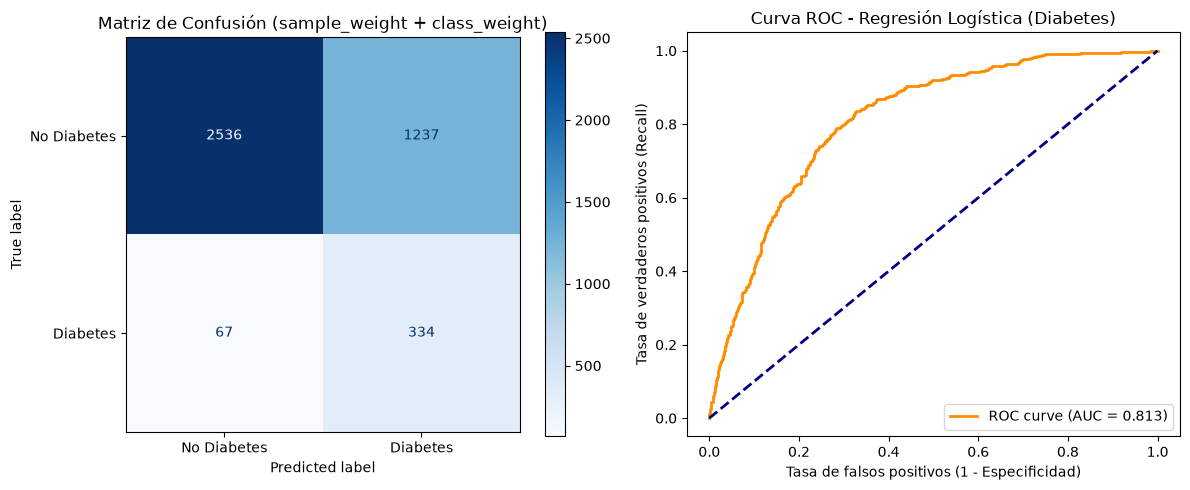

In [45]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_diab = reg_log_diab.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (sample_weight + class_weight)")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [5]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8491 | Recall test: 0.8329
Diferencia: 0.0162


In [46]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_diab >= u).astype(int)
    report = classification_report(
        y_test_diab, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]

    print(
        f"Umbral {u:.2f} -> Recall Diabetes: {rec*100:.2f}% | Precisión Diabetes: {prec*100:.2f}% | F1: {f1:.4f}"
    )

Umbral 0.35 -> Recall Diabetes: 90.52% | Precisión Diabetes: 17.46% | F1: 0.2927
Umbral 0.40 -> Recall Diabetes: 88.03% | Precisión Diabetes: 18.57% | F1: 0.3067
Umbral 0.45 -> Recall Diabetes: 85.29% | Precisión Diabetes: 19.88% | F1: 0.3225
Umbral 0.50 -> Recall Diabetes: 83.29% | Precisión Diabetes: 21.26% | F1: 0.3387
Umbral 0.55 -> Recall Diabetes: 79.30% | Precisión Diabetes: 22.35% | F1: 0.3487


DIABETES CON SMOTE
              precision    recall  f1-score   support

           0     0.9667    0.7315    0.8328      3773
           1     0.2320    0.7631    0.3558       401

    accuracy                         0.7345      4174
   macro avg     0.5994    0.7473    0.5943      4174
weighted avg     0.8961    0.7345    0.7870      4174

ROC-AUC Score: 0.8132


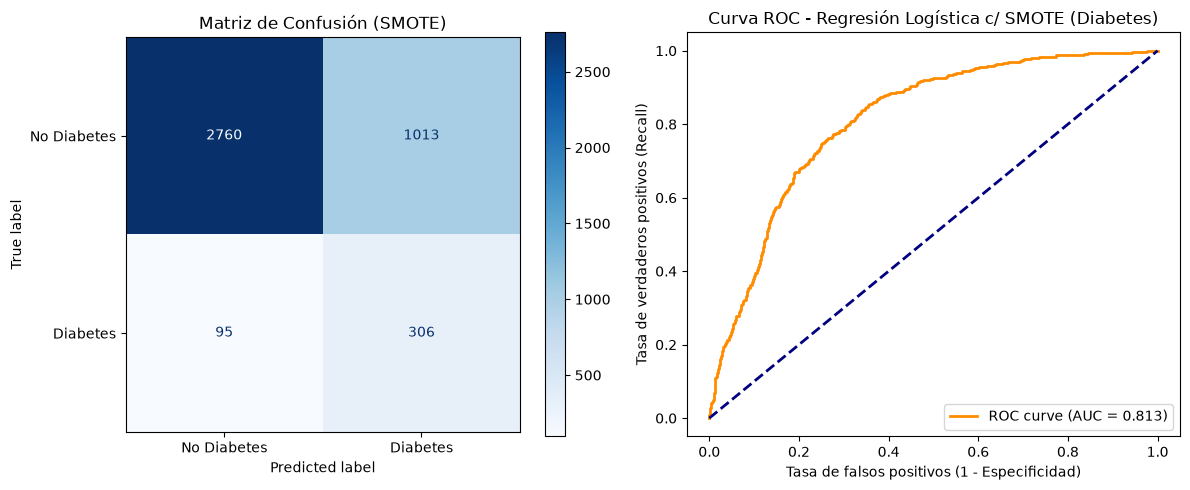

In [47]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_diab_smote = reg_log_diab_smote.predict(X_test_diab)
y_proba_diab_smote = reg_log_diab_smote.predict_proba(X_test_diab)[:, 1]

print("DIABETES CON SMOTE")
print(classification_report(y_test_diab, y_pred_diab_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_diab, y_proba_diab_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_diab, y_proba_diab_smote)
auc_smote = roc_auc_score(y_test_diab, y_proba_diab_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística c/ SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab_smote.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab_smote.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7718 | Recall test: 0.7631
Diferencia: 0.0087


### CONCLUSIONES

El modelo seleccionado como Baseline es el de class_weight='balanced' y FACTORADULTO, sobre el cual se aplicó una optimización de umbral de decisión en 0.40. Esta combinación maximiza la capacidad de detección temprana, alcanzando una Sensibilidad(Recall) del 88.03% en el grupo de riesgo de diabetes. Fue necesario bajar el umbral para no dejar pasar tantos enfermos. 


# EVALUACIÓN MODELO RANDOM FOREST 

In [7]:
# Cargar modelo Random Forest

rf_diab_class_weight = joblib.load("../models/random_forest_diab_class_weight.joblib")
rf_diab = joblib.load("../models/random_forest_diab.joblib")
rf_smote_diab = joblib.load("../models/rf_smote_diabetes.joblib")
brf_diabetes = joblib.load("../models/balanced_random_forest_diab.joblib")
rf_subsample = joblib.load("../models/subsample_random_forest_diab.joblib")
brf_sample_weight_diab= joblib.load("../models/brf_sample_weight_diab.joblib")
brf_opt_gridsearch= joblib.load("../models/brf_hta_opt_gridsearch.joblib")


INFORME DE CLASIFICACIÓN - RF class_weight DIABETES
              precision    recall  f1-score   support

           0     0.9183    0.9647    0.9409      3773
           1     0.3667    0.1920    0.2520       401

    accuracy                         0.8905      4174
   macro avg     0.6425    0.5784    0.5965      4174
weighted avg     0.8653    0.8905    0.8748      4174

ROC-AUC Score: 0.8037


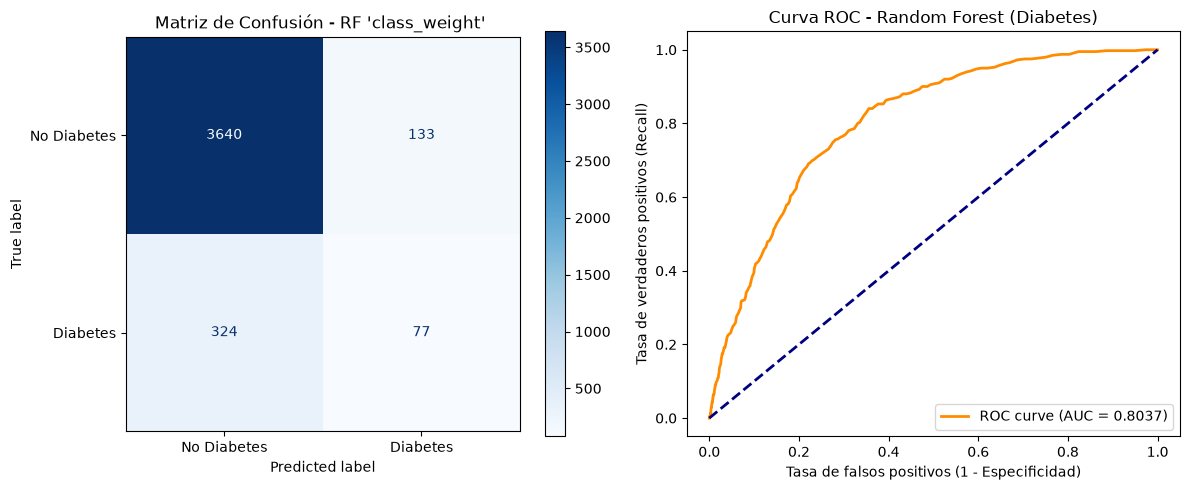

In [49]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - DIABETES
# ========================================================

# Predicciones 
y_pred_rf_diab_class_weight = rf_diab_class_weight.predict(X_test_diab)
y_proba_rf_diab_class_weight = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight DIABETES")
print(classification_report(y_test_diab, y_pred_rf_diab_class_weight, digits=4))

# ROC-AUC 
auc_rf_diab_class_weight = roc_auc_score(y_test_diab, y_proba_rf_diab_class_weight)
print(f"ROC-AUC Score: {auc_rf_diab_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF 'class_weight' ")

# Curva ROC
fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, _ = roc_curve(y_test_diab, y_proba_rf_diab_class_weight)
axes[1].plot(fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_diab_class_weight.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_diab_class_weight.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.1920
Diferencia: 0.8080


In [50]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,92.02%,15.48%,0.2650,32
1,0.15,86.53%,18.65%,0.3068,54
2,0.20,78.30%,20.84%,0.3291,87
3,0.25,70.82%,23.91%,0.3575,117
4,0.30,60.85%,25.82%,0.3626,157
5,0.50,19.45%,36.79%,0.2545,323


INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight
              precision    recall  f1-score   support

           0     0.9244    0.9372    0.9308      3773
           1     0.3209    0.2793    0.2987       401

    accuracy                         0.8740      4174
   macro avg     0.6227    0.6082    0.6147      4174
weighted avg     0.8665    0.8740    0.8700      4174

ROC-AUC Score: 0.8025


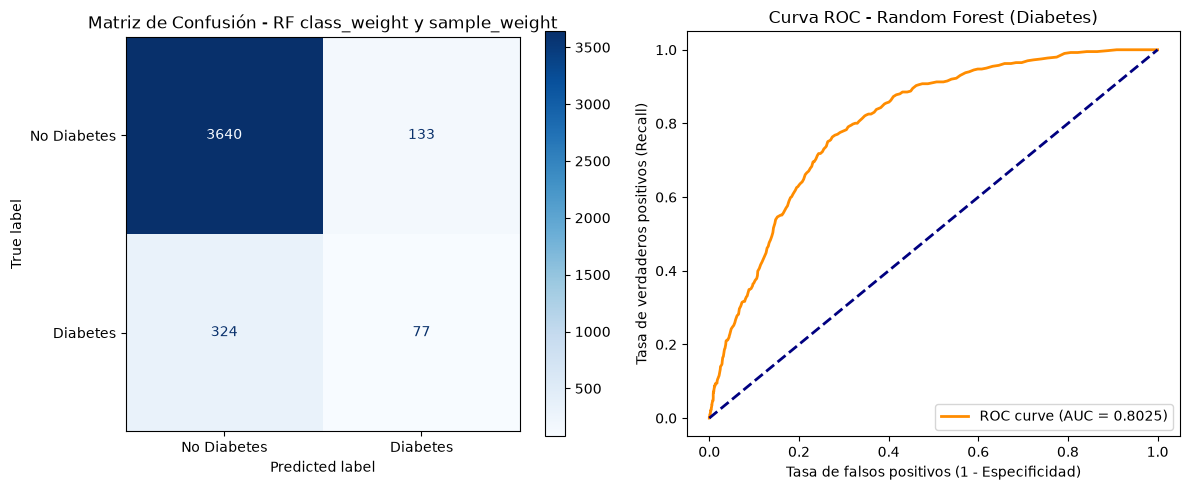

In [51]:
# ==========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') Y 'sample_weight' 
# ==========================================================

# Predicciones 
y_pred_rf_diab= rf_diab.predict(X_test_diab)
y_proba_rf_diab = rf_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight")
print(classification_report(y_test_diab, y_pred_rf_diab, digits=4))

# ROC-AUC 
auc_rf_diab = roc_auc_score(y_test_diab, y_proba_rf_diab)
print(f"ROC-AUC Score: {auc_rf_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF class_weight y sample_weight")

# Curva ROC
fpr_rf_diab, tpr_rf_diab, _ = roc_curve(y_test_diab, y_proba_rf_diab)
axes[1].plot(fpr_rf_diab, tpr_rf_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9938 | Recall test: 0.2793
Diferencia: 0.7145


In [52]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,92.27%,15.11%,0.2596,30
1,0.15,88.53%,17.73%,0.2955,45
2,0.20,82.54%,19.56%,0.3163,70
3,0.25,77.56%,22.03%,0.3431,90
4,0.30,69.58%,24.03%,0.3572,122
5,0.50,28.18%,31.48%,0.2974,288


INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.9152    0.9666    0.9402      3773
           1     0.3333    0.1571    0.2136       401

    accuracy                         0.8888      4174
   macro avg     0.6243    0.5619    0.5769      4174
weighted avg     0.8593    0.8888    0.8704      4174

ROC-AUC Score: 0.7991


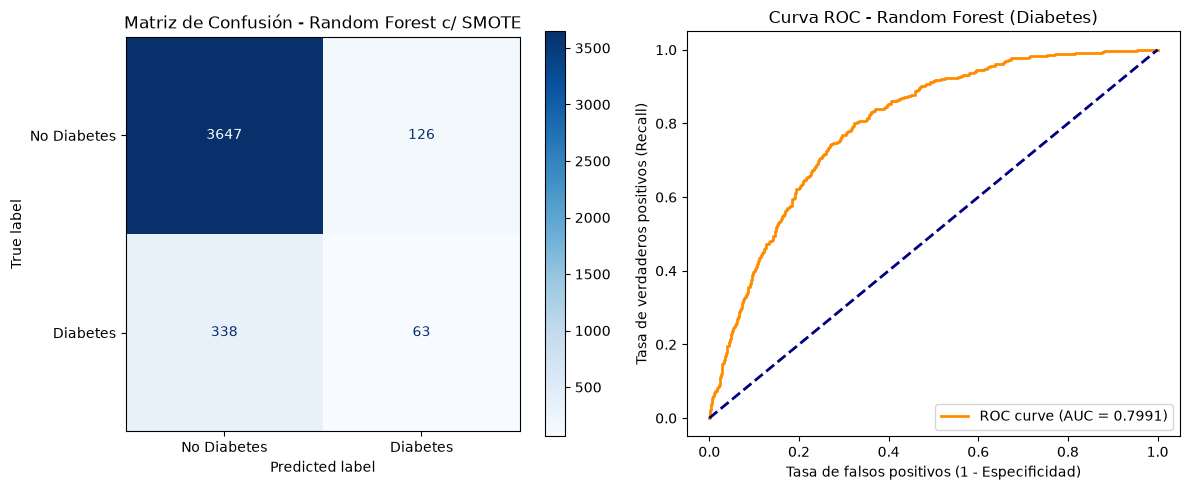

In [53]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_diab = rf_smote_diab.predict(X_test_diab)
y_proba_rf_smote_diab = rf_smote_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_diab, y_pred_rf_smote_diab, digits=4))

# ROC-AUC 
auc_rf_smote_diab = roc_auc_score(y_test_diab, y_proba_rf_smote_diab)
print(f"ROC-AUC Score: {auc_rf_smote_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_diab = confusion_matrix(y_test_diab, y_pred_rf_smote_diab)
disp_rf_smote_diab = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_diab, display_labels=["No Diabetes", "Diabetes"])
disp_rf_smote_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest c/ SMOTE")

# Curva ROC
fpr_rf_smote_diab, tpr_rf_smote_diab, _ = roc_curve(y_test_diab, y_proba_rf_smote_diab)
axes[1].plot(fpr_rf_smote_diab, tpr_rf_smote_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_smote_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_smote_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.3204 | Recall test: 0.1571
Diferencia: 0.1633


In [54]:
# Evaluar probabilidades del modelo entrenado con SMOTE
y_proba_smote = rf_smote_diab.predict_proba(X_test_diab)[:, 1]

# Barrido rápido para ver Falsos Positivos vs Recall
for u in [0.20, 0.30, 0.40, 0.50]:
    y_pred_u = (y_proba_smote >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    recall = tp / (tp + fn)
    print(f"Umbral {u:.2f} | Recall: {recall*100:.2f}% | Falsos Positivos: {fp} | Falsos Negativos: {fn}")

Umbral 0.20 | Recall: 79.05% | Falsos Positivos: 1209 | Falsos Negativos: 84
Umbral 0.30 | Recall: 59.35% | Falsos Positivos: 700 | Falsos Negativos: 163
Umbral 0.40 | Recall: 36.41% | Falsos Positivos: 351 | Falsos Negativos: 255
Umbral 0.50 | Recall: 15.71% | Falsos Positivos: 126 | Falsos Negativos: 338


INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.9504    0.7970    0.8669      3773
           1     0.2416    0.6085    0.3459       401

    accuracy                         0.7789      4174
   macro avg     0.5960    0.7027    0.6064      4174
weighted avg     0.8823    0.7789    0.8169      4174

ROC-AUC Score: 0.7955


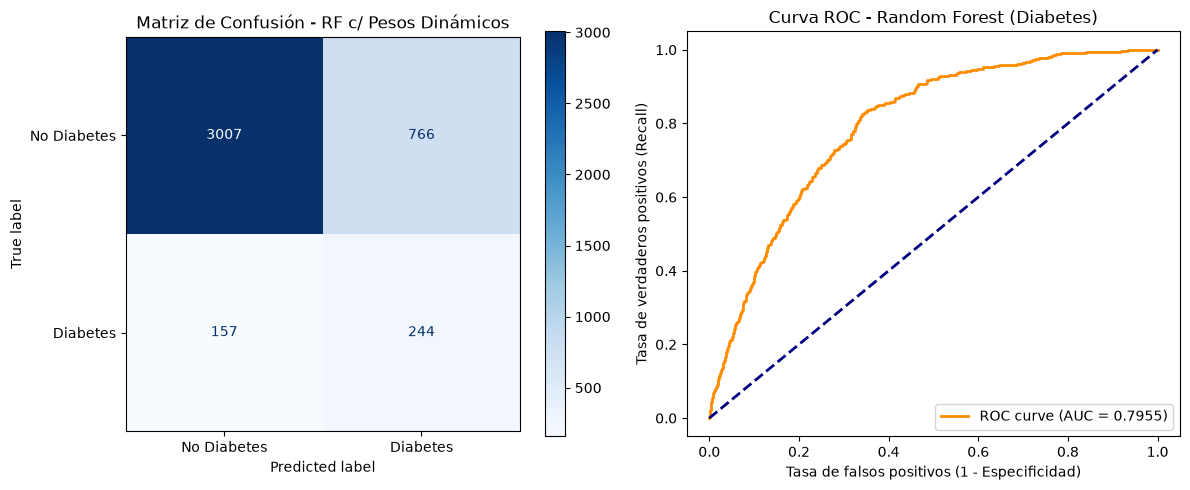

In [55]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample.predict(X_test_diab)
y_proba_rf_subsample = rf_subsample.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_diab, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_diab, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_diab, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No Diabetes", "Diabetes"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF c/ Pesos Dinámicos")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_diab, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_subsample.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_subsample.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_subsample.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8884 | Recall test: 0.6085
Diferencia: 0.2799


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)
              precision    recall  f1-score   support

           0     0.9547    0.7935    0.8667      3773
           1     0.2495    0.6459    0.3600       401

    accuracy                         0.7793      4174
   macro avg     0.6021    0.7197    0.6133      4174
weighted avg     0.8870    0.7793    0.8180      4174

ROC-AUC Score: 0.8041


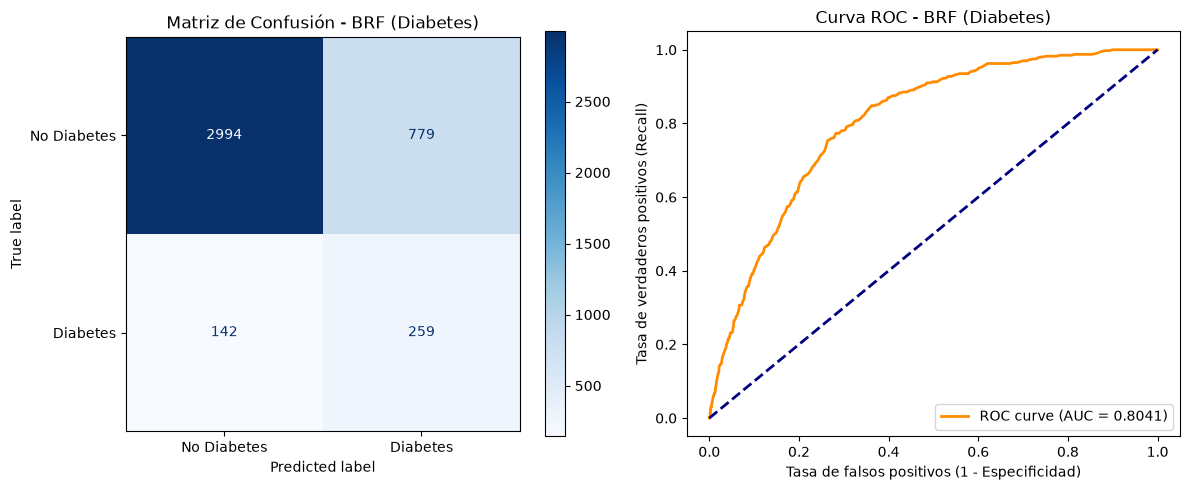

In [56]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_diabetes = brf_diabetes.predict(X_test_diab)
y_proba_brf_diabetes = brf_diabetes.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diabetes, digits=4))

# ROC-AUC 
auc_brf_diabetes = roc_auc_score(y_test_diab, y_proba_brf_diabetes)
print(f"ROC-AUC Score: {auc_brf_diabetes:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diabetes = confusion_matrix(y_test_diab, y_pred_brf_diabetes)
disp_brf_diabetes = ConfusionMatrixDisplay(confusion_matrix=cm_brf_diabetes, display_labels=["No Diabetes", "Diabetes"])
disp_brf_diabetes.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF (Diabetes)")

# Curva ROC
fpr_brf_diabetes, tpr_brf_diabetes, _ = roc_curve(y_test_diab, y_proba_brf_diabetes)
axes[1].plot(fpr_brf_diabetes, tpr_brf_diabetes, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_diabetes:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_diabetes.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_diabetes.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_diabetes.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.6459
Diferencia: 0.3541


,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Diabéticos No Detectados)
0,0.20,97.26%,13.05%,0.2301,10
1,0.25,95.26%,14.22%,0.2474,19
2,0.30,92.27%,15.42%,0.2643,30
3,0.35,90.02%,16.82%,0.2835,40
4,0.40,87.28%,18.07%,0.2994,50
5,0.45,83.79%,19.51%,0.3165,65
6,0.50,78.80%,20.98%,0.3314,85


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO
              precision    recall  f1-score   support

           0     0.9681    0.6846    0.8020      3773
           1     0.2098    0.7880    0.3314       401

    accuracy                         0.6945      4174
   macro avg     0.5890    0.7363    0.5667      4174
weighted avg     0.8953    0.6945    0.7568      4174

ROC-AUC Score: 0.8031


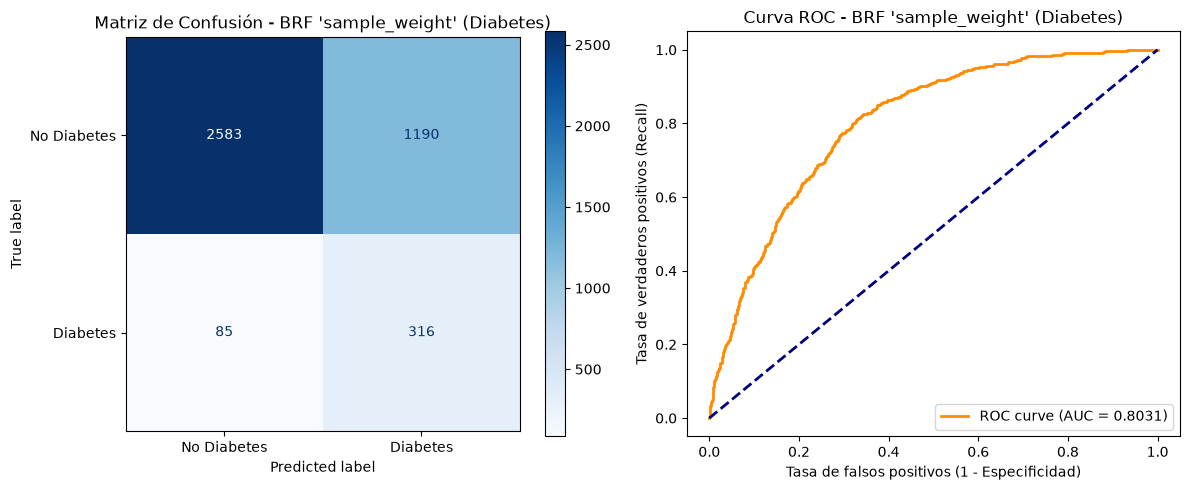

In [57]:
# =================================================================
# EVALUACIÓN Balanced Random Forest 'class_weight' + FACTOR ADULTO 
# =================================================================

# Predicciones 
y_pred_sample_weight_diab = brf_sample_weight_diab.predict(X_test_diab)
y_proba_sample_weight_diab = brf_sample_weight_diab.predict_proba(X_test_diab)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_sample_weight_diab >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Diabéticos No Detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO")
print(classification_report(y_test_diab, y_pred_sample_weight_diab, digits=4))

# ROC-AUC 
auc_sample_weight_diab = roc_auc_score(y_test_diab, y_proba_sample_weight_diab)
print(f"ROC-AUC Score: {auc_sample_weight_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_sample_weight_diab = confusion_matrix(y_test_diab, y_pred_sample_weight_diab)
disp_sample_weight_diab = ConfusionMatrixDisplay(confusion_matrix=cm_sample_weight_diab, display_labels=["No Diabetes", "Diabetes"])
disp_sample_weight_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF 'sample_weight' (Diabetes)")

# Curva ROC
fpr_sample_weight_diab, tpr_sample_weight_diab, _ = roc_curve(y_test_diab, y_proba_sample_weight_diab)
axes[1].plot(fpr_sample_weight_diab, tpr_sample_weight_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_sample_weight_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF 'sample_weight' (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_sample_weight_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [13]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_sample_weight_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_sample_weight_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9165 | Recall test: 0.7880
Diferencia: 0.1284


INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)
              precision    recall  f1-score   support

           0     0.9806    0.5770    0.7265      3773
           1     0.1832    0.8928    0.3040       401

    accuracy                         0.6073      4174
   macro avg     0.5819    0.7349    0.5153      4174
weighted avg     0.9040    0.6073    0.6859      4174

ROC-AUC Score: 0.8026


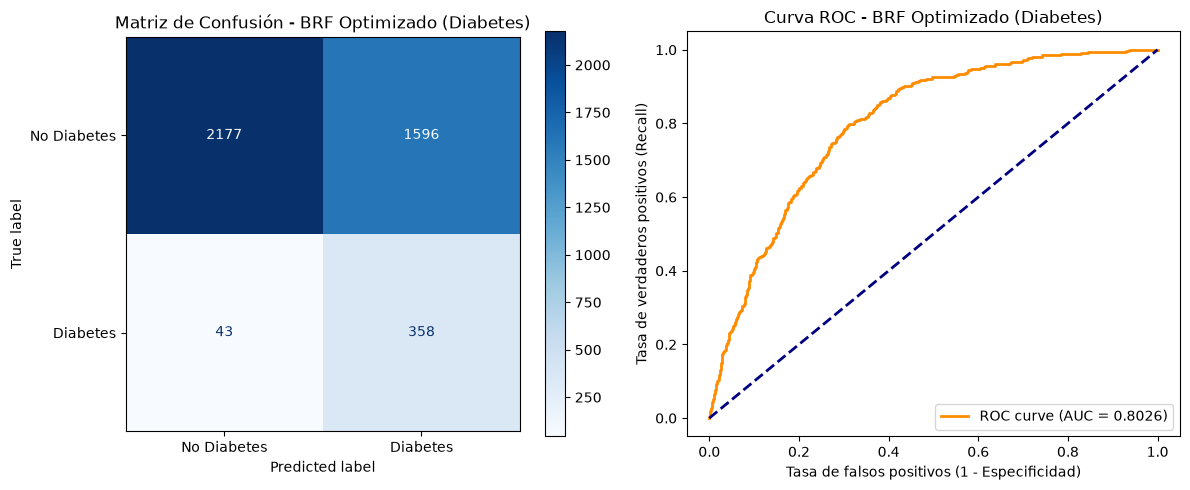

In [58]:
# ==========================================================
# EVALUACIÓN BALANCED RANDOM FOREST OPTIMIZADO (DIABETES)
# ==========================================================

# Predicciones
y_pred_brf_diab = brf_opt_gridsearch.predict(X_test_diab)
y_proba_brf_diab = brf_opt_gridsearch.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diab, digits=4))

# ROC-AUC
auc_brf_diab = roc_auc_score(y_test_diab, y_proba_brf_diab)
print(f"ROC-AUC Score: {auc_brf_diab:.4f}")

# Matriz de confusión + Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diab = confusion_matrix(y_test_diab, y_pred_brf_diab)
disp_brf_diab = ConfusionMatrixDisplay(
    confusion_matrix=cm_brf_diab,
    display_labels=["No Diabetes", "Diabetes"]
)
disp_brf_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF Optimizado (Diabetes)")

fpr_brf_diab, tpr_brf_diab, _ = roc_curve(y_test_diab, y_proba_brf_diab)
axes[1].plot(fpr_brf_diab, tpr_brf_diab, color="darkorange", lw=2,
             label=f"ROC curve (AUC = {auc_brf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_opt_gridsearch.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_opt_gridsearch.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_opt_gridsearch.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.8928
Diferencia: 0.1072


In [59]:
import numpy as np

# Probabilidades predichas del BRF optimizado
y_pred_proba_brf_diab = brf_opt_gridsearch.predict_proba(X_test_diab)[:, 1]

# 2. Rango extendido de umbrales
umbrales = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
evaluacion_brf = []

for u in umbrales:
    y_pred_u = (y_pred_proba_brf_diab >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_brf.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_brf = pd.DataFrame(evaluacion_brf)
display(df_umbrales_brf)

# 3. Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_diab, y_pred_proba_brf_diab)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.1,1.0000,0.1018,0.1848,0,3539
1,0.2,0.9875,0.1178,0.2104,5,2967
2,0.3,0.9601,0.1361,0.2384,16,2444
3,0.4,0.9252,0.1584,0.2705,30,1971
4,0.5,0.8928,0.1832,0.3040,43,1596
5,0.6,0.8055,0.2076,0.3301,78,1233
6,0.7,0.6608,0.2356,0.3473,136,860



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.62


El modelo Balanced Random Forest Classifier optimizado (con max_depth=12, submuestreo nativo auto e incorporación de FACTORADULTO) demostró ser la arquitectura basada en ensambles más efectiva. A diferencia de las aproximaciones sintéticas como SMOTE, este enfoque eliminó el sesgo de la clase mayoritaria sin generar sobreajuste al ruido, alcanzando una sensibilidad (Recall) del 78.80% bajo el umbral estándar de 0.50 y hasta un 83.79% ajustando el umbral a 0.45. Estos resultados consolidan a Balanced Random Forest como una alternativa competitiva frente a la Regresión Logística en tareas de cribado epidemiológico.

# SVM

In [15]:
# Cargar datos

svm_diab_cw = joblib.load("../models/svm_hta_diab.joblib")
svm_diab = joblib.load("../models/svm_diab.joblib")
svm_diab_smote = joblib.load("../models/svm_diab_smote.joblib")
svm_diab_opt = joblib.load("../models/svm_diab_optimizado.joblib")


INFORME DE CLASIFICACIÓN - SVM 'class_weight' (Diabetes)
              precision    recall  f1-score   support

           0     0.9559    0.7649    0.8498      3773
           1     0.2320    0.6683    0.3445       401

    accuracy                         0.7556      4174
   macro avg     0.5940    0.7166    0.5971      4174
weighted avg     0.8864    0.7556    0.8013      4174

ROC-AUC Score: 0.7914


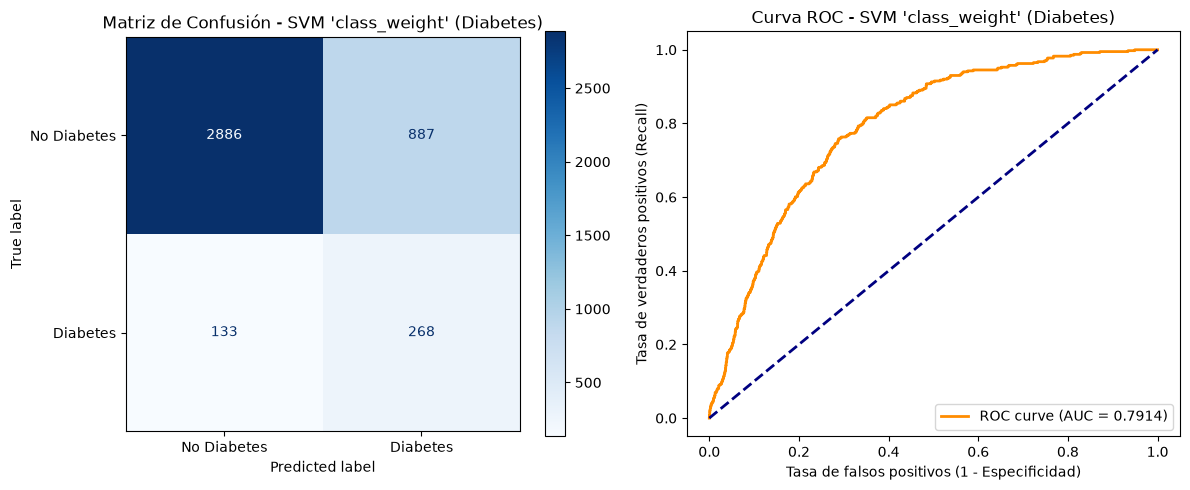

In [61]:
# =========================================
# EVALUACIÓN SVM 'class_weight' - DIABETES
# ==========================================

# Predicciones 
y_pred_svm_diab_cw = svm_diab_cw.predict(X_test_diab)
y_pred_proba_svm_diab_cw = svm_diab_cw.predict_proba(X_test_diab)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM 'class_weight' (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_cw, digits=4))

# ROC-AUC
auc_svm_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_cw)
print(f"ROC-AUC Score: {auc_svm_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_cw = confusion_matrix(y_test_diab,y_pred_svm_diab_cw)
disp_svm_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' (Diabetes)")

# CURVA ROC 
fpr_svm_diab_cw, tpr_svm_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_cw)
axes[1].plot(fpr_svm_diab_cw, tpr_svm_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM 'class_weight' (Diabetes)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/svm_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_cw.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_cw.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9632 | Recall test: 0.6683
Diferencia: 0.2949


INFORME DE CLASIFICACIÓN - SVM (Diabetes)
              precision    recall  f1-score   support

           0     0.9507    0.7864    0.8607      3773
           1     0.2346    0.6160    0.3398       401

    accuracy                         0.7700      4174
   macro avg     0.5926    0.7012    0.6003      4174
weighted avg     0.8819    0.7700    0.8107      4174

ROC-AUC Score: 0.7911


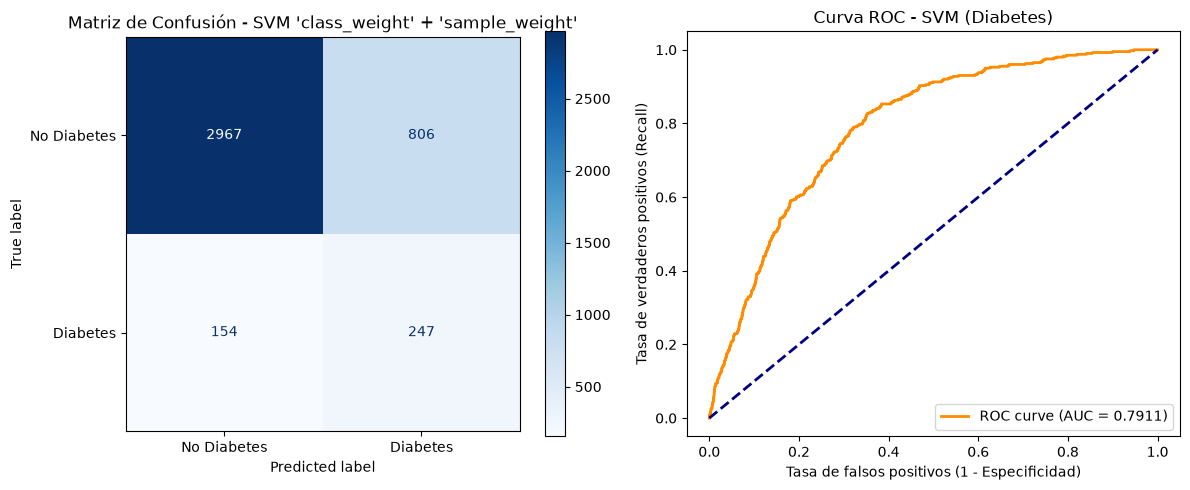

In [62]:
# =========================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight'- DIABETES
# =========================================================

# Predicciones 
y_pred_svm_diab = svm_diab.predict(X_test_diab)
y_pred_proba_svm_diab = svm_diab.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab, digits=4))

# ROC-AUC
auc_svm_diab = roc_auc_score(y_test_diab, y_pred_proba_svm_diab)
print(f"ROC-AUC Score: {auc_svm_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab = confusion_matrix(y_test_diab,y_pred_svm_diab)
disp_svm_diab = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' + 'sample_weight'")

# CURVA ROC 
fpr_svm_diab, tpr_svm_diab, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab)
axes[1].plot(fpr_svm_diab, tpr_svm_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9015 | Recall test: 0.6160
Diferencia: 0.2855


INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9374    0.8579    0.8959      3773
           1     0.2566    0.4613    0.3298       401

    accuracy                         0.8198      4174
   macro avg     0.5970    0.6596    0.6128      4174
weighted avg     0.8720    0.8198    0.8415      4174

ROC-AUC Score: 0.7650


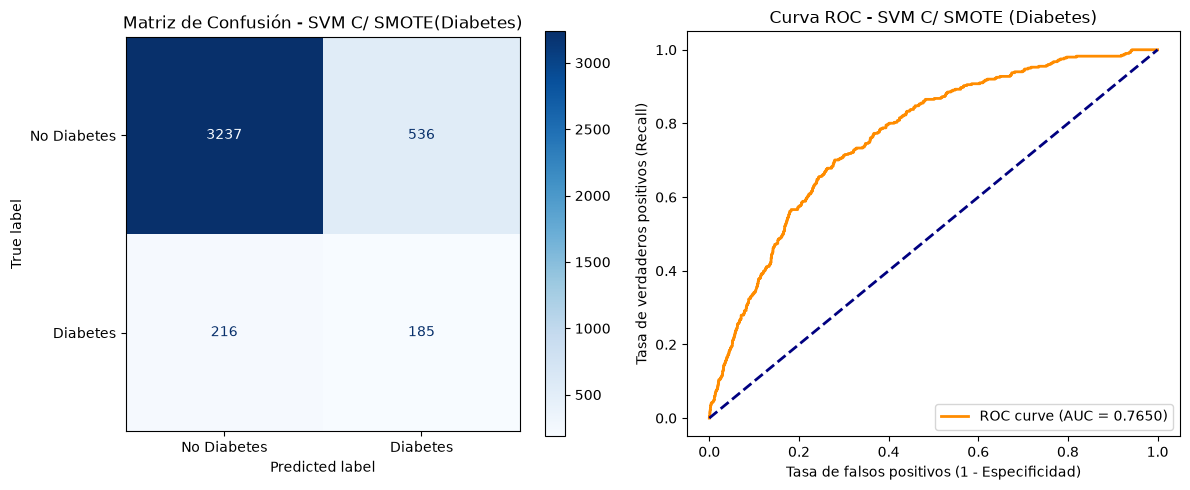

In [63]:
# ====================================
# EVALUACIÓN SVM CON SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichas
y_pred_svm_diab_smote = svm_diab_smote.predict(X_test_diab)
y_pred_proba_svm_diab_smote = svm_diab_smote.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_smote, digits=4))

# ROC-AUC
auc_svm_diab_smote = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_smote)
print(f"ROC-AUC Score: {auc_svm_diab_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_smote = confusion_matrix(y_test_diab,y_pred_svm_diab_smote)
disp_svm_diab_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_smote, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM C/ SMOTE(Diabetes)")

# CURVA ROC 
fpr_svm_diab_smote, tpr_svm_diab_smote, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_smote)
axes[1].plot(fpr_svm_diab_smote, tpr_svm_diab_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM C/ SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_smote.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_smote.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9202 | Recall test: 0.4613
Diferencia: 0.4589


INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO (Diabetes)
              precision    recall  f1-score   support

           0     0.9507    0.7864    0.8607      3773
           1     0.2346    0.6160    0.3398       401

    accuracy                         0.7700      4174
   macro avg     0.5926    0.7012    0.6003      4174
weighted avg     0.8819    0.7700    0.8107      4174

ROC-AUC Score: 0.8099


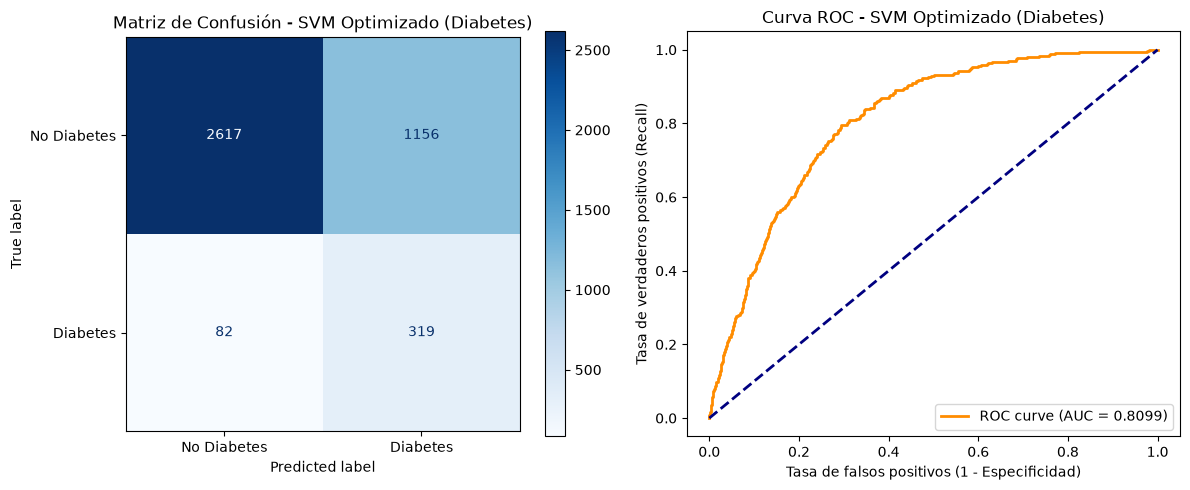

In [64]:
# ====================================
# EVALUACIÓN SVM OPTIMIZADO - DIABETES
# ====================================

# Predicciones 
y_pred_svm_diab_opt = svm_diab_opt.predict(X_test_diab)
y_pred_proba_svm_diab_opt = svm_diab_opt.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab, digits=4))

# ROC-AUC
auc_svm_diab_opt = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_opt)
print(f"ROC-AUC Score: {auc_svm_diab_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_opt = confusion_matrix(y_test_diab,y_pred_svm_diab_opt)
disp_svm_diab_opt = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_opt, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM Optimizado (Diabetes)")

# CURVA ROC 
fpr_svm_diab_opt, tpr_svm_diab_opt, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_opt)
axes[1].plot(fpr_svm_diab_opt, tpr_svm_diab_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_opt:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_opt.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_opt.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8441 | Recall test: 0.7955
Diferencia: 0.0486


In [65]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Probabilidades predichas del SVM optimizado
y_pred_proba_svm_diab_opt = svm_diab_opt.predict_proba(X_test_diab)[:, 1]

# Rango extendido de umbrales
umbrales = [0.10, 0.15, 0.20, 0.25, 0.26, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_svm = []

for u in umbrales:
    y_pred_u = (y_pred_proba_svm_diab_opt >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_svm.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_svm = pd.DataFrame(evaluacion_svm)
display(df_umbrales_svm)

# Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_diab, y_pred_proba_svm_diab_opt)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.10,0.7681,0.2278,0.3514,93,1044
1,0.15,0.6309,0.2533,0.3614,148,746
2,0.20,0.5137,0.2893,0.3702,195,506
3,0.25,0.3840,0.3105,0.3434,247,342
4,0.26,0.3441,0.3087,0.3255,263,309
5,0.30,0.2718,0.3303,0.2982,292,221
6,0.35,0.1796,0.3582,0.2392,329,129
7,0.40,0.1022,0.3565,0.1589,360,74
8,0.45,0.0648,0.4561,0.1135,375,31
9,0.50,0.0299,0.4615,0.0562,389,14



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.09


# EVALUACIÓN MODELOS XGBOOST

In [20]:
# CARGAR DATOS
xgb_model_cw_diab = joblib.load("../models/xgb_model_cw_diab.joblib")
xgb_model_diab = joblib.load("../models/xgb_model_diab.joblib")
xgb_model_smote_diab = joblib.load("../models/xgb_model_smote_diab.joblib")
xgb_diab_opt = joblib.load("../models/xgb_diab_optimizado.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)
              precision    recall  f1-score   support

           0     0.9517    0.7779    0.8561      3773
           1     0.2312    0.6284    0.3380       401

    accuracy                         0.7635      4174
   macro avg     0.5914    0.7032    0.5970      4174
weighted avg     0.8825    0.7635    0.8063      4174

ROC-AUC Score: 0.7975


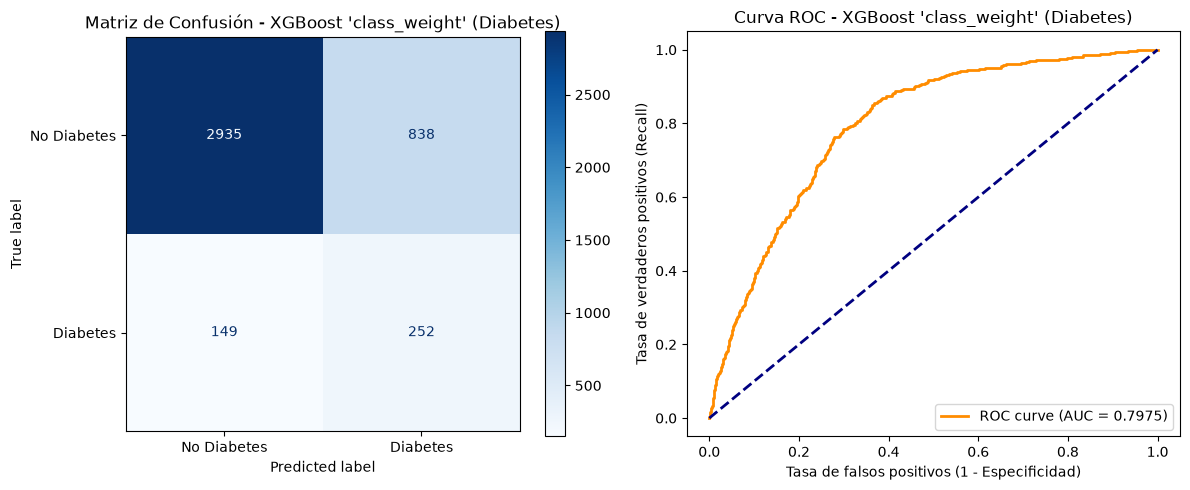

In [68]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - DIABETES
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab_cw = xgb_model_cw_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab_cw = xgb_model_cw_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab_cw, digits=4))

# ROC-AUC
auc_xgb_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab_cw)
print(f"ROC-AUC Score: {auc_xgb_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab_cw = confusion_matrix(y_test_diab, y_pred_xgb_diab_cw)
disp_xgb_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost 'class_weight' (Diabetes)")

# Curva ROC
fpr_xgb_diab_cw, tpr_xgb_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab_cw)
axes[1].plot(fpr_xgb_diab_cw, tpr_xgb_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab_cw:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost 'class_weight' (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_cw_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_cw_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9595 | Recall test: 0.6284
Diferencia: 0.3310


INFORME DE CLASIFICACIÓN - XGBOOST 'class_weight' y 'sample_weight' (Diabetes)
              precision    recall  f1-score   support

           0     0.9512    0.7949    0.8660      3773
           1     0.2419    0.6160    0.3474       401

    accuracy                         0.7777      4174
   macro avg     0.5965    0.7054    0.6067      4174
weighted avg     0.8830    0.7777    0.8162      4174

ROC-AUC Score: 0.7933


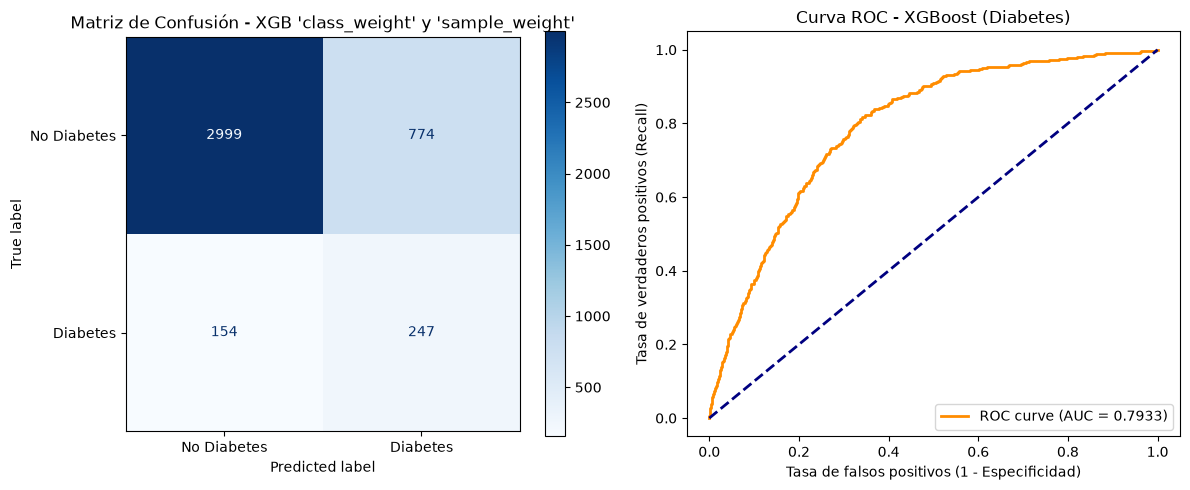

In [69]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - DIABETES
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab = xgb_model_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab = xgb_model_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST 'class_weight' y 'sample_weight' (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab, digits=4))

# ROC-AUC
auc_xgb_diab = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab)
print(f"ROC-AUC Score: {auc_xgb_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab = confusion_matrix(y_test_diab, y_pred_xgb_diab)
disp_xgb_diab = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGB 'class_weight' y 'sample_weight'")

# Curva ROC
fpr_xgb_diab, tpr_xgb_diab, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab)
axes[1].plot(fpr_xgb_diab, tpr_xgb_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9208 | Recall test: 0.6160
Diferencia: 0.3049


INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9102    0.9809    0.9443      3773
           1     0.3333    0.0898    0.1415       401

    accuracy                         0.8953      4174
   macro avg     0.6218    0.5353    0.5429      4174
weighted avg     0.8548    0.8953    0.8671      4174

ROC-AUC Score: 0.8113


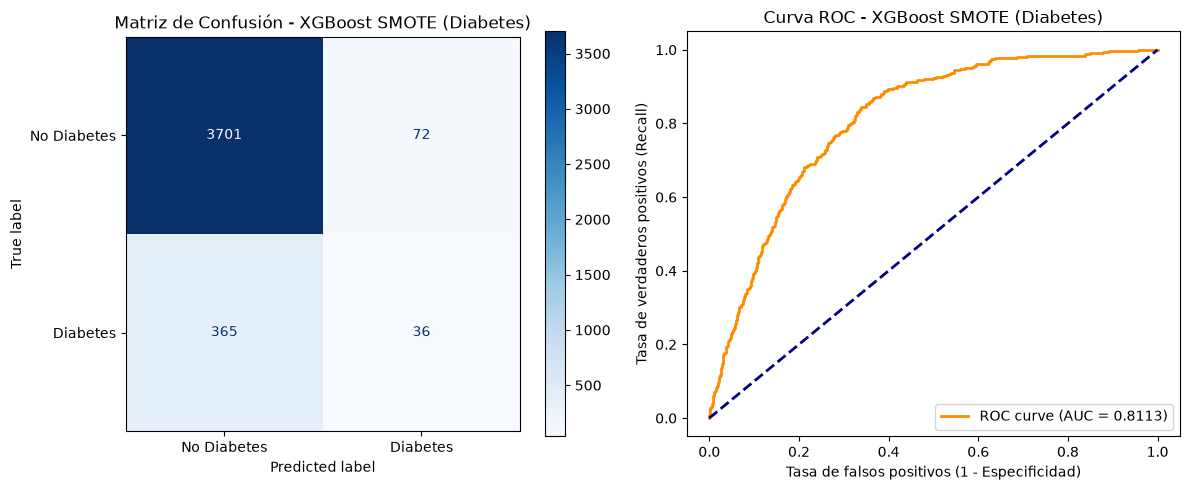

In [70]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_smote = xgb_model_smote_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_diab, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_diab, y_pred_xgb_smote)
disp_xgb_smote= ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost SMOTE (Diabetes)")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_diab, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_smote_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_smote_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.2113 | Recall test: 0.0898
Diferencia: 0.1216


INFORME DE CLASIFICACIÓN - XGBOOST Optimizado (Diabetes)
              precision    recall  f1-score   support

           0     0.9677    0.7148    0.8223      3773
           1     0.2242    0.7756    0.3479       401

    accuracy                         0.7207      4174
   macro avg     0.5960    0.7452    0.5851      4174
weighted avg     0.8963    0.7207    0.7767      4174

ROC-AUC Score: 0.8116


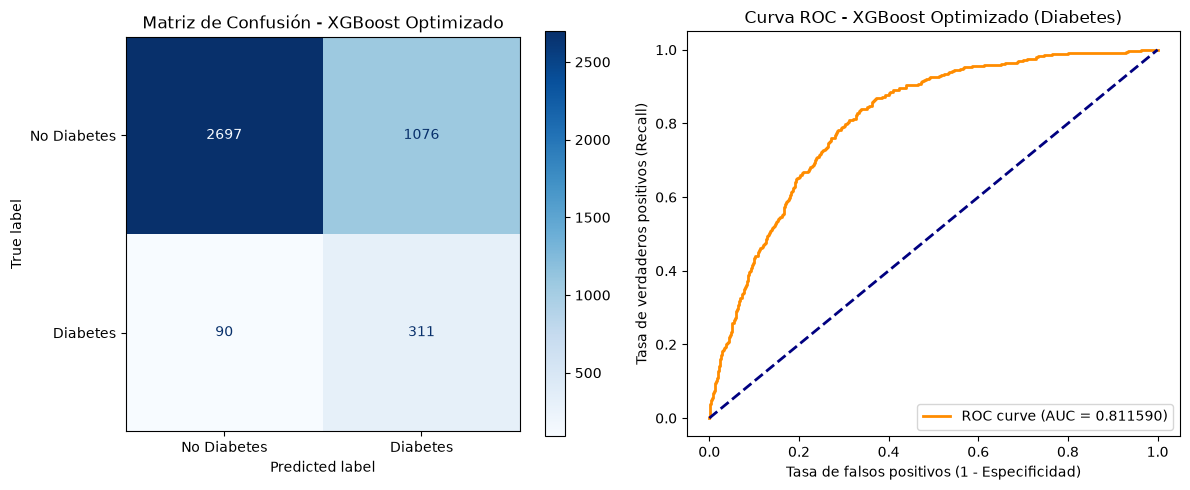

In [71]:
# ========================================
# EVALUACIÓN XGBOOST OPTIMIZADO - DIABETES
# ========================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab_opt = xgb_diab_opt.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab_opt = xgb_diab_opt.predict(X_test_diab)

print("INFORME DE CLASIFICACIÓN - XGBOOST Optimizado (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab_opt, digits=4))

# ROC-AUC
auc_xgb_diab_opt = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab_opt)
print(f"ROC-AUC Score: {auc_xgb_diab_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab_opt = confusion_matrix(y_test_diab, y_pred_xgb_diab_opt)
disp_xgb_diab_opt = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab_opt, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Optimizado")

# Curva ROC
fpr_xgb_diab_opt, tpr_xgb_diab_opt, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab_opt)
axes[1].plot(fpr_xgb_diab_opt, tpr_xgb_diab_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab_opt:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_diab_opt.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_diab_opt.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8348 | Recall test: 0.7756
Diferencia: 0.0592


In [72]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_proba_opt = xgb_diab_opt.predict_proba(X_test_diab)[:, 1]
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_umbrales = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)

    # Extraer directamente la matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_umbrales.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_corregido = pd.DataFrame(evaluacion_umbrales)
display(df_umbrales_corregido)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.20,0.9252,0.1615,0.2750,30,1926
1,0.25,0.9052,0.1728,0.2902,38,1738
2,0.30,0.8928,0.1831,0.3039,43,1597
3,0.35,0.8753,0.1921,0.3151,50,1476
4,0.40,0.8479,0.2008,0.3247,61,1353
5,0.45,0.8155,0.2096,0.3335,74,1233
6,0.50,0.7756,0.2242,0.3479,90,1076


In [73]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular FPR, TPR y umbrales de la curva ROC
fpr, tpr, thresholds = roc_curve(y_test_diab, y_proba_opt)

# Índice de Youden: J = Sensibilidad - FPR (ya que FPR = 1 - Especificidad)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
opt_threshold = thresholds[opt_idx]

print(f"El umbral óptimo según el Índice de Youden es: {opt_threshold:.2f}")

El umbral óptimo según el Índice de Youden es: 0.43


# EVALUACIÓN POR MODELO

In [25]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

#  Función de coloración
def colorear_metricas(val, metrica):
    if pd.isna(val):
        return ''
    
    if metrica == 'ROC-AUC Test':
        if val < 0.60: return 'background-color: #f8d7da; color: #721c24;'
        elif val < 0.70: return 'background-color: #ffeba8; color: #856404;'
        elif val < 0.80: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #28a745; color: white;'

    elif metrica == 'Recall Test':
        if val >= 0.80: return 'background-color: #28a745; color: white;'
        elif val >= 0.60: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #f8d7da; color: #721c24;'

    elif metrica == 'Precision Test':
        if val < 0.20: return 'background-color: #f8d7da; color: #721c24;'
        return ''

    elif metrica == 'F1-Score Test':
        if val < 0.50: return 'background-color: #f8d7da; color: #721c24;'
        elif val <= 0.65: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    elif metrica == 'Dif. Recall (Train - Test)':
        mag = abs(val)
        if mag > 0.10: return 'background-color: #f8d7da; color: #721c24;'
        elif mag >= 0.05: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    return ''

# 2. Función reutilizable para generar y estilizar la tabla
def generar_tabla_comparativa(diccionario_modelos, X_train, y_train, X_test, y_test):
    resultados = []

    for nombre, modelo in diccionario_modelos.items():
        y_pred_train = modelo.predict(X_train)
        y_pred_test = modelo.predict(X_test)
        y_proba_test = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
        
        acc_test = accuracy_score(y_test, y_pred_test)
        recall_train = recall_score(y_train, y_pred_train)
        recall_test = recall_score(y_test, y_pred_test)
        diff_recall = recall_train - recall_test 
        
        resultados.append({
            'Modelo': nombre,
            'Accuracy Test': round(acc_test, 4),
            'Recall Test': round(recall_test, 4),
            'Dif. Recall (Train - Test)': round(diff_recall, 4),
            'Precision Test': round(precision_score(y_test, y_pred_test), 4),
            'F1-Score Test': round(f1_score(y_test, y_pred_test), 4),
            'ROC-AUC Test': round(roc_auc_score(y_test, y_proba_test), 4)
        })

    df = pd.DataFrame(resultados).sort_values(by='ROC-AUC Test', ascending=False).reset_index(drop=True)

    styler = df.style.format({
        'Accuracy Test': '{:.4f}',
        'Recall Test': '{:.4f}',
        'Dif. Recall (Train - Test)': '{:.4f}',
        'Precision Test': '{:.4f}',
        'F1-Score Test': '{:.4f}',
        'ROC-AUC Test': '{:.4f}'
    })

    for col in df.columns:
        if col != 'Modelo':
            styler = styler.map(lambda v, c=col: colorear_metricas(v, c), subset=[col])

    return styler

In [26]:
import os
import dataframe_image as dfi

# 1. Definir los modelos
modelos_rl_diab = {
    'Regresión Logística (Class Weight)': reg_log_diab_class_weight,
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_diab,
    'Regresión Logística (SMOTE)': reg_log_diab_smote
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_rl_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_regresion_logistica_diabetes.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight),0.7209,0.7830,0.0187,0.2256,0.3503,0.8146
1,Regresión Logística (SMOTE),0.7345,0.7631,0.0087,0.2320,0.3558,0.8132
2,Regresión Logística (Class Weight + Sample Weight),0.6876,0.8329,0.0162,0.2126,0.3387,0.8128


In [27]:
modelos_rf_diab = {
    'Random Forest (Class Weight)': rf_diab_class_weight,
    'Random Forest (Class Weight + Sample Weight)': rf_diab,
    'Random Forest (SMOTE)': rf_smote_diab,
    'Random Forest c/ pesos dinámicos': rf_subsample,
    'Balanced Random Forest': brf_diabetes,
    'Balanced Random Forest (Sample Weight)': brf_sample_weight_diab,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch
    }

# Generar la tabla coloreada reutilizando la función
tabla_estilizada = generar_tabla_comparativa(modelos_rf_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_random_forest_diabetes.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Balanced Random Forest,0.7793,0.6459,0.3541,0.2495,0.3600,0.8041
1,Random Forest (Class Weight),0.8905,0.1920,0.8080,0.3667,0.2520,0.8037
2,Balanced Random Forest (Sample Weight),0.6945,0.7880,0.1284,0.2098,0.3314,0.8031
3,Balanced Random Forest Optimizado,0.6073,0.8928,0.1072,0.1832,0.3040,0.8026
4,Random Forest (Class Weight + Sample Weight),0.8740,0.2793,0.7145,0.3209,0.2987,0.8025
5,Random Forest (SMOTE),0.8888,0.1571,0.1633,0.3333,0.2136,0.7991
6,Random Forest c/ pesos dinámicos,0.7789,0.6085,0.2799,0.2416,0.3459,0.7955


In [28]:
modelos_svm_diab = {
    'SVM (Class Weight)': svm_diab_cw,
    'SVM (Class Weight + Sample Weight)': svm_diab,
    'SVM (SMOTE)': svm_diab_smote,
    'SVM Optimizado': svm_diab_opt
}

tabla_estilizada = generar_tabla_comparativa(modelos_svm_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_svm_diabetes.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,SVM Optimizado,0.7034,0.7955,0.0486,0.2163,0.3401,0.8099
1,SVM (Class Weight),0.7556,0.6683,0.2949,0.2320,0.3445,0.7914
2,SVM (Class Weight + Sample Weight),0.7700,0.6160,0.2855,0.2346,0.3398,0.7911
3,SVM (SMOTE),0.8198,0.4613,0.4589,0.2566,0.3298,0.7650


In [29]:
modelos_xgb_diab ={
    'XGBoost (Class Weight)': xgb_model_cw_diab,
    'XGBoost (Class Weight + Sample Weight)': xgb_model_diab,
    'XGBoost (SMOTE)': xgb_model_smote_diab,
    'XGBoost Optimizado': xgb_diab_opt
}


# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_xgb_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_xgboost_diabetes.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7207,0.7756,0.0592,0.2242,0.3479,0.8116
1,XGBoost (SMOTE),0.8953,0.0898,0.1216,0.3333,0.1415,0.8113
2,XGBoost (Class Weight),0.7635,0.6284,0.3310,0.2312,0.3380,0.7975
3,XGBoost (Class Weight + Sample Weight),0.7777,0.6160,0.3049,0.2419,0.3474,0.7933


# TABLA COMPARATIVA DE MEJORES RESULTADOS POR MODELO

In [30]:
tabla_comparativa_final = {
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_diab,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch,
    'SVM Optimizado': svm_diab_opt,
    'XGBoost Optimizado': xgb_diab_opt
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(tabla_comparativa_final, X_train_diab, y_train_diab, X_test_diab, y_test_diab)
# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'tabla_comparativa_final_diabetes.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight + Sample Weight),0.6876,0.8329,0.0162,0.2126,0.3387,0.8128
1,XGBoost Optimizado,0.7207,0.7756,0.0592,0.2242,0.3479,0.8116
2,SVM Optimizado,0.7034,0.7955,0.0486,0.2163,0.3401,0.8099
3,Balanced Random Forest Optimizado,0.6073,0.8928,0.1072,0.1832,0.3040,0.8026
